# KEBA AI Coding Contest 2026 — Level 1
### Final Pipeline with LightGBM



---
## Upload Data

In [1]:
try:
    from google.colab import files
    print('Upload level_1_train.csv and level_1_test_submission.csv')
    _ = files.upload()
except ImportError:
    print('Running locally — CSV files should be in this folder')


Upload level_1_train.csv and level_1_test_submission.csv


Saving level_1_test_submission.csv to level_1_test_submission (1).csv
Saving level_1_train.csv to level_1_train (1).csv


---
## Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from lightgbm import LGBMClassifier
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss
from sklearn.calibration import calibration_curve

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
BLUE, GREEN, RED = "#2980b9", "#2ecc71", "#e74c3c"


---
## Load Data & Feature Engineering


In [3]:
print("\n[1/8] Loading data...")

train = pd.read_csv("level_1_train.csv",          sep=";")
test  = pd.read_csv("level_1_test_submission.csv", sep=";")
train["ds"] = pd.to_datetime(train["ds"])
test["ds"]  = pd.to_datetime(test["ds"])

if "y_e" in train.columns: train.drop(columns=["y_e"], inplace=True)
if "y_e" in test.columns:  test.drop(columns=["y_e"], inplace=True)

train = train.sort_values(["unique_id", "ds"]).reset_index(drop=True)

print(f"    Train : {len(train):,} rows  "
      f"{train['ds'].min().date()} → {train['ds'].max().date()}")
print(f"    Test  : {len(test):,} rows   "
      f"{test['ds'].min().date()} → {test['ds'].max().date()}")
print(f"    Users : {train['unique_id'].nunique()}")
print(f"    Global charge rate : {train['y_b'].mean():.2%}")

# Every date below has 0% charging in training — confirmed from data.

print("\n[2/8] Defining zero-charging days...")

ZERO_DATES_TRAIN = pd.to_datetime([
    "2024-01-01", "2024-01-03", "2024-01-05", "2024-01-06",
    "2024-03-29", "2024-04-01", "2024-05-01", "2024-05-09",
    "2024-05-19", "2024-05-20", "2024-05-30", "2024-05-31",
    "2024-08-15", "2024-10-26", "2024-11-01", "2024-12-08",
    "2024-12-24", "2024-12-25", "2024-12-26", "2024-12-27",
    "2024-12-30", "2024-12-31", "2025-01-01", "2025-01-06",
]).date

ZERO_DATES_TEST = pd.to_datetime([
    "2025-04-18",   # Good Friday
    "2025-04-21",   # Easter Monday
    "2025-05-01",   # Labour Day
    "2025-05-29",   # Ascension Day
    "2025-05-30",   # Bridge day after Ascension
]).date

print("[3/8] Engineering features...")

def add_time_features(df, zero_dates):
    df = df.copy()
    df["date"]       = df["ds"].dt.date
    df["hour"]       = df["ds"].dt.hour
    df["dow"]        = df["ds"].dt.dayofweek
    df["month"]      = df["ds"].dt.month
    df["week"]       = df["ds"].dt.isocalendar().week.astype(int)
    df["year"]       = df["ds"].dt.year
    df["yearweek"]   = df["year"] * 100 + df["week"]
    df["dayofyear"]  = df["ds"].dt.dayofyear
    df["hour_sin"]   = np.sin(2 * np.pi * df["hour"]  / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * df["hour"]  / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * df["dow"]   / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * df["dow"]   / 7)
    df["week_sin"]   = np.sin(2 * np.pi * df["week"]  / 52)
    df["week_cos"]   = np.cos(2 * np.pi * df["week"]  / 52)
    df["month_sin"]  = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"]  = np.cos(2 * np.pi * df["month"] / 12)
    df["is_zero"]    = (
        df["date"].isin(zero_dates) | (df["dow"] >= 5)
    ).astype(int)
    return df

train = add_time_features(train, ZERO_DATES_TRAIN)
test  = add_time_features(test,  ZERO_DATES_TEST)

ZERO_RATE = float(train[train["is_zero"] == 1]["y_b"].mean())
print(f"    Zero-day prediction value  : {ZERO_RATE:.5f}")
print(f"    Active-day charge rate     : "
      f"{train[train['is_zero']==0]['y_b'].mean():.4f}")



[1/8] Loading data...
    Train : 164,160 rows  2024-01-01 → 2025-03-31
    Test  : 21,960 rows   2025-04-01 → 2025-05-31
    Users : 15
    Global charge rate : 5.77%

[2/8] Defining zero-charging days...
[3/8] Engineering features...
    Zero-day prediction value  : 0.00228
    Active-day charge rate     : 0.0849


In [4]:
def build_recency_features(tr_ref, target_df, hl=50):
    """
    Exponential-decay weighted means (half-life = 50 days).
    Recent weeks count more — important for users whose behaviour changed.
    """
    tr    = tr_ref[tr_ref["is_zero"] == 0].copy()
    max_d = tr["ds"].max()
    tr["days_ago"] = (max_d - tr["ds"]).dt.total_seconds() / 86400
    tr["w"]        = np.exp(-np.log(2) * tr["days_ago"] / hl)
    glob           = float(tr["y_b"].mean())

    def wm(g):
        return float(np.dot(g["w"].values, g["y_b"].values) / g["w"].sum())

    rw_hdow = tr.groupby(["unique_id", "hour", "dow"]).apply(wm)
    rw_h    = tr.groupby(["unique_id", "hour"]).apply(wm)
    rw_u    = tr.groupby("unique_id").apply(wm)

    # Recency-weighted weekly participation rate
    wk_w = tr.groupby("yearweek")["w"].mean()
    wkly = tr.groupby(["unique_id","hour","dow","yearweek"])["y_b"].max().reset_index()
    wkly = wkly.join(wk_w.rename("ww"), on="yearweek")
    rw_wr = wkly.groupby(["unique_id","hour","dow"]).apply(
        lambda g: float(np.dot(g["ww"].values, g["y_b"].values) / g["ww"].sum())
    )

    # Day decomposition: P(charges today | dow) × P(hour | charging today)
    daily = tr.groupby(["unique_id","date"])["y_b"].max().reset_index()
    daily["dow"]      = pd.to_datetime(daily["date"]).dt.dayofweek
    daily["days_ago"] = (
        max_d - pd.to_datetime(daily["date"])
    ).dt.total_seconds() / 86400
    daily["w"] = np.exp(-np.log(2) * daily["days_ago"] / hl)
    p_day = daily.groupby(["unique_id","dow"]).apply(
        lambda g: float(np.dot(g["w"].values, g["y_b"].values) / g["w"].sum())
    ).rename("p_day")

    cd = tr[tr["y_b"]==1].groupby("unique_id")["date"].apply(set)
    ph = []
    for uid in tr["unique_id"].unique():
        u    = tr[tr["unique_id"]==uid]
        u_on = u[u["date"].isin(cd.get(uid, set()))]
        if len(u_on) > 0:
            ph.append(u_on.groupby(["unique_id","hour"])["y_b"].mean())
    p_h = (pd.concat(ph).rename("p_h")
           if ph else pd.Series(name="p_h", dtype=float))

    df = target_df.copy()
    for s, k, n in [
        (rw_wr,  ["unique_id","hour","dow"], "rw_wr"),
        (rw_hdow,["unique_id","hour","dow"], "rw_hdow"),
        (rw_h,   ["unique_id","hour"],       "rh"),
        (rw_u,   ["unique_id"],              "ru"),
        (p_day,  ["unique_id","dow"],        "p_day"),
        (p_h,    ["unique_id","hour"],       "p_h"),
    ]:
        df = df.join(s.rename(n), on=k)

    for c in ["rw_wr","rw_hdow","rh","ru","p_day","p_h"]:
        df[c] = df[c].fillna(glob)

    df["base"]      = df["rw_wr"].fillna(df["rw_hdow"]).fillna(df["rh"]).fillna(df["ru"])
    df["decomp"]    = df["p_day"] * df["p_h"]
    df["stat_pred"] = 0.65 * df["base"] + 0.35 * df["decomp"]
    return df


def add_weekly_features(target_df, ref_df, windows=(16, 20, 26)):
    """
    Weekly same-slot history — the strongest single feature class.
    week_N = mean of last N observations at this (user, dow, hour) slot.
    Leakage-safe: only ref_df labels used.
    """
    df = target_df.copy()
    for w in windows:
        df[f"wk_{w}"] = np.nan

    for uid in df["unique_id"].unique():
        ref_u = ref_df[ref_df["unique_id"] == uid]
        for h in range(24):
            for d in range(7):
                vals = ref_u[
                    (ref_u["hour"] == h) & (ref_u["dow"] == d)
                ]["y_b"].values
                if len(vals) == 0:
                    continue
                mask = (
                    (df["unique_id"] == uid) &
                    (df["hour"] == h) &
                    (df["dow"] == d)
                )
                if not mask.any():
                    continue
                for w in windows:
                    v = vals[-w:]
                    if len(v) > 0:
                        df.loc[mask, f"wk_{w}"] = float(v.sum()) / len(v)
    return df


def add_target_encodings(target_df, ref_df):
    """Leakage-safe target encodings — fitted on ref_df only."""
    df   = target_df.copy()
    glob = float(ref_df["y_b"].mean())
    for col, keys in [
        ("te_user_dow_hour", ["unique_id","dow","hour"]),
        ("te_dow_hour",      ["dow","hour"]),
    ]:
        te  = ref_df.groupby(keys)["y_b"].mean().rename(col)
        df  = df.join(te, on=keys)
        df[col] = df[col].fillna(glob)
    return df


FEAT_COLS = [
    "hour", "dow", "month", "week", "dayofyear",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "week_sin", "week_cos", "month_sin", "month_cos",
    "is_zero",
    "rw_wr", "rw_hdow", "rh", "ru", "p_day", "p_h", "base", "decomp",
    "wk_16", "wk_20", "wk_26",
    "te_user_dow_hour", "te_dow_hour",
]

FILL_COLS = ["wk_16","wk_20","wk_26","te_user_dow_hour","te_dow_hour"]

LGBM_PARAMS = dict(
    n_estimators=300, learning_rate=0.05, num_leaves=15,
    min_child_samples=10, subsample=0.8, colsample_bytree=0.8,
    random_state=42, verbose=-1,
)

# Blend weights — tuned via grid search:
#   alpha_wk=0.60 best on rolling CV
#   alpha_lgbm=0.10 best on rolling CV
ALPHA_WK   = 0.60   # weekly same-slot features
ALPHA_LGBM = 0.10   # per-user LightGBM
ALPHA_STAT = 1 - ALPHA_WK - ALPHA_LGBM   # = 0.30 recency-weighted statistical

# Confidence-adaptive LightGBM weight:
#   when stat prior is very confident (|p - 0.5| > 0.30), use less ML
#   when uncertain, let ML contribute more
CONF_THRESH  = 0.30
ALPHA_CONF   = 0.04   # low alpha when stat is confident
ALPHA_UNCONF = 0.12   # higher alpha when stat is uncertain




In [5]:
def predict_blend(tr_f, target_f, ref_df, adaptive=True):
    """
    Full prediction pipeline for a target dataframe.
    tr_f     = training features (for fitting LightGBM)
    target_f = features for the target set (val or test)
    ref_df   = raw reference data (for filling NaNs)
    """
    glob = float(ref_df[ref_df["is_zero"]==0]["y_b"].mean())
    tgt  = target_f.copy()
    tgt["lgbm"] = tgt["stat_pred"].copy()

    for uid in sorted(train["unique_id"].unique()):
        tr_u = tr_f[tr_f["unique_id"]==uid][FEAT_COLS+["y_b"]].dropna()
        te_u = tgt[tgt["unique_id"]==uid][FEAT_COLS]
        if tr_u["y_b"].sum() < 5 or tr_u["y_b"].nunique() < 2:
            continue
        m = LGBMClassifier(**LGBM_PARAMS)
        m.fit(tr_u[FEAT_COLS], tr_u["y_b"])
        tgt.loc[tgt["unique_id"]==uid, "lgbm"] = \
            m.predict_proba(te_u[FEAT_COLS])[:, 1]

    if adaptive:
        confidence = np.abs(tgt["stat_pred"] - 0.5)
        alpha_ml   = np.where(confidence > CONF_THRESH, ALPHA_CONF, ALPHA_UNCONF)
        alpha_s    = 1 - ALPHA_WK - alpha_ml
        blend = alpha_s * tgt["stat_pred"] + ALPHA_WK * tgt["wk_16"] + alpha_ml * tgt["lgbm"]
    else:
        blend = (
            ALPHA_STAT * tgt["stat_pred"] +
            ALPHA_WK   * tgt["wk_16"] +
            ALPHA_LGBM * tgt["lgbm"]
        )

    tgt["y_prob"] = np.where(
        tgt["is_zero"] == 1,
        ZERO_RATE,
        blend
    ).clip(1e-5, 1 - 1e-5)

    return tgt

print("\n[4/8] Rolling monthly cross-validation (8 folds)...")

MONTHLY_FOLDS = [
    ("2024-08-01", "2024-08-31"),
    ("2024-09-01", "2024-09-30"),
    ("2024-10-01", "2024-10-31"),
    ("2024-11-01", "2024-11-30"),
    ("2024-12-01", "2024-12-31"),
    ("2025-01-01", "2025-01-31"),
    ("2025-02-01", "2025-02-28"),
    ("2025-03-01", "2025-03-31"),
]

cv_results = []
for val_s, val_e in MONTHLY_FOLDS:
    tr_m = train[train["ds"] <  val_s].copy()
    vl_m = train[(train["ds"] >= val_s) & (train["ds"] <= val_e)].copy()
    if len(tr_m) == 0 or len(vl_m) == 0:
        continue

    tr_mf = build_recency_features(tr_m, tr_m)
    vl_mf = build_recency_features(tr_m, vl_m)
    tr_mf = add_weekly_features(tr_mf, tr_m)
    vl_mf = add_weekly_features(vl_mf, tr_m)
    tr_mf = add_target_encodings(tr_mf, tr_m)
    vl_mf = add_target_encodings(vl_mf, tr_m)

    gm = float(tr_m[tr_m["is_zero"]==0]["y_b"].mean())
    for df in [tr_mf, vl_mf]:
        for c in FILL_COLS:
            df[c] = df[c].fillna(gm)

    vl_pred = predict_blend(tr_mf, vl_mf, tr_m, adaptive=True)

    bs  = brier_score_loss(vl_pred["y_b"], vl_pred["y_prob"])
    auc = roc_auc_score(vl_pred["y_b"],    vl_pred["y_prob"]) \
          if vl_pred["y_b"].nunique() > 1 else float("nan")
    ll  = log_loss(vl_pred["y_b"],         vl_pred["y_prob"]) \
          if vl_pred["y_b"].nunique() > 1 else float("nan")

    cv_results.append({
        "period": f"{val_s[:7]}",
        "brier":  bs,
        "auc":    auc,
        "logloss":ll,
        "n":      len(vl_m),
    })
    print(f"    {val_s[:7]}  Brier={bs:.5f}  "
          f"AUC={auc:.4f}  LogLoss={ll:.5f}  (n={len(vl_m):,})")

cv_df = pd.DataFrame(cv_results)
print()
print(f"    Rolling mean  Brier={cv_df['brier'].mean():.5f}  "
      f"AUC={cv_df['auc'].mean():.4f}  "
      f"LogLoss={cv_df['logloss'].mean():.5f}")
print(f"    Rolling std   Brier={cv_df['brier'].std():.5f}")
print(f"    Min / Max     {cv_df['brier'].min():.5f} / {cv_df['brier'].max():.5f}")



[4/8] Rolling monthly cross-validation (8 folds)...
    2024-08  Brier=0.03518  AUC=0.9426  LogLoss=0.11566  (n=10,815)
    2024-09  Brier=0.03199  AUC=0.9540  LogLoss=0.11164  (n=10,455)
    2024-10  Brier=0.04012  AUC=0.9368  LogLoss=0.12731  (n=10,815)
    2024-11  Brier=0.03849  AUC=0.9273  LogLoss=0.13419  (n=10,455)
    2024-12  Brier=0.03734  AUC=0.9404  LogLoss=0.12821  (n=10,815)
    2025-01  Brier=0.03409  AUC=0.9653  LogLoss=0.10924  (n=10,815)
    2025-02  Brier=0.03430  AUC=0.9632  LogLoss=0.10685  (n=9,735)
    2025-03  Brier=0.03303  AUC=0.9435  LogLoss=0.11486  (n=10,815)

    Rolling mean  Brier=0.03557  AUC=0.9466  LogLoss=0.11849
    Rolling std   Brier=0.00282
    Min / Max     0.03199 / 0.04012


In [6]:
print("\n[5/8] Single validation split (last 61 days)...")

VAL_DAYS  = 61
val_start = train["ds"].max() - pd.Timedelta(days=VAL_DAYS)
tr_split  = train[train["ds"] <  val_start].copy()
vl_split  = train[train["ds"] >= val_start].copy()

tr_f = build_recency_features(tr_split, tr_split)
vl_f = build_recency_features(tr_split, vl_split)
tr_f = add_weekly_features(tr_f, tr_split)
vl_f = add_weekly_features(vl_f, tr_split)
tr_f = add_target_encodings(tr_f, tr_split)
vl_f = add_target_encodings(vl_f, tr_split)

g_split = float(tr_split[tr_split["is_zero"]==0]["y_b"].mean())
for df in [tr_f, vl_f]:
    for c in FILL_COLS:
        df[c] = df[c].fillna(g_split)

vl_pred = predict_blend(tr_f, vl_f, tr_split, adaptive=True)

bs  = brier_score_loss(vl_pred["y_b"], vl_pred["y_prob"])
auc = roc_auc_score(vl_pred["y_b"],    vl_pred["y_prob"])
ll  = log_loss(vl_pred["y_b"],         vl_pred["y_prob"])



[5/8] Single validation split (last 61 days)...


---
## Metrics!

In [7]:
print("\n" + "━"*55)
print("  SINGLE SPLIT (last 61 days)")
print(f"  Brier Score  : {bs:.5f}   (lower = better, 0 = perfect)")
print(f"  ROC-AUC      : {auc:.4f}   (higher = better, 1 = perfect)")
print(f"  Log Loss     : {ll:.5f}   (lower = better)")
print(f"  Pred mean    : {vl_pred['y_prob'].mean():.5f}")
print(f"  Actual mean  : {vl_pred['y_b'].mean():.5f}")
print("━"*55)



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  SINGLE SPLIT (last 61 days)
  Brier Score  : 0.03435   (lower = better, 0 = perfect)
  ROC-AUC      : 0.9520   (higher = better, 1 = perfect)
  Log Loss     : 0.11336   (lower = better)
  Pred mean    : 0.05666
  Actual mean  : 0.05838
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━



[6/8] Generating evaluation charts...


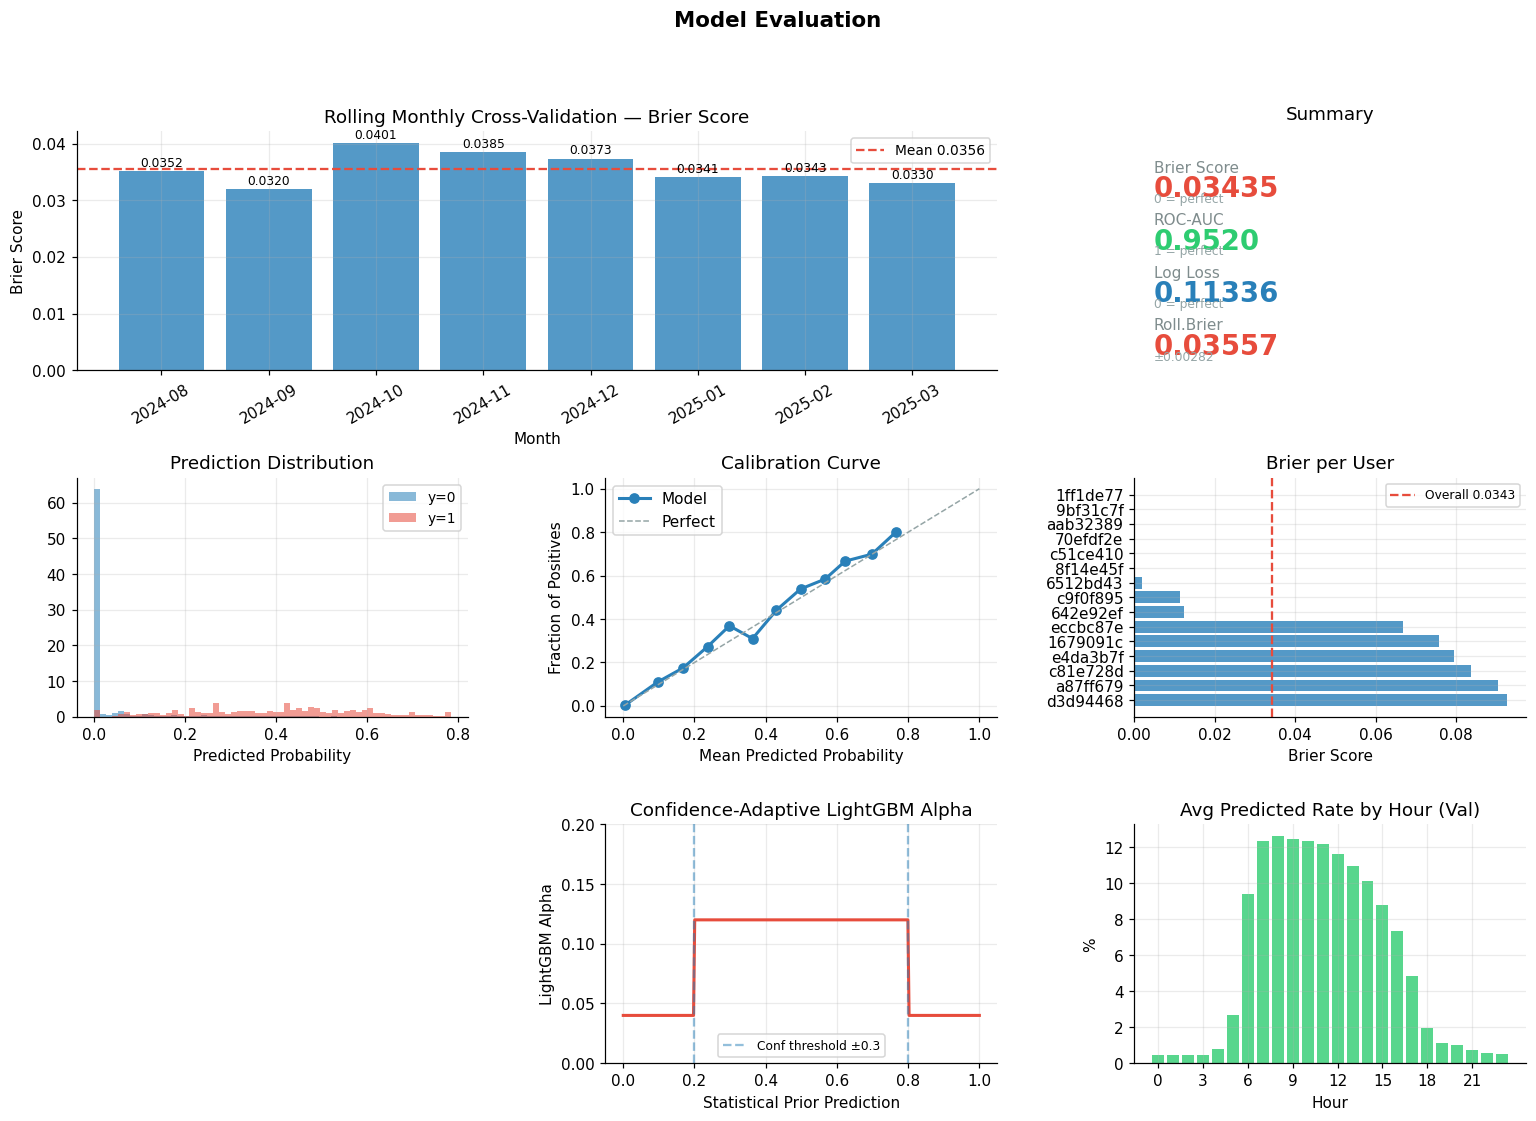

    Saved: evaluation.png


In [8]:
print("\n[6/8] Generating evaluation charts...")

fig = plt.figure(figsize=(17, 11))
fig.suptitle("Model Evaluation", fontsize=14, fontweight="bold")
gs  = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.35)

# 1 — Rolling CV Brier by month
ax = fig.add_subplot(gs[0, :2])
bars = ax.bar(cv_df["period"], cv_df["brier"], color=BLUE, alpha=0.8)
ax.axhline(cv_df["brier"].mean(), color=RED, linestyle="--", lw=1.5,
           label=f"Mean {cv_df['brier'].mean():.4f}")
ax.set_title("Rolling Monthly Cross-Validation — Brier Score")
ax.set_xlabel("Month"); ax.set_ylabel("Brier Score")
ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=9)
for bar, val in zip(bars, cv_df["brier"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0003,
            f"{val:.4f}", ha="center", va="bottom", fontsize=8)

# 2 — Metric summary
ax = fig.add_subplot(gs[0, 2]); ax.axis("off")
for i, (name, val, note, col) in enumerate([
    ("Brier Score",  f"{bs:.5f}",  "0 = perfect",  RED),
    ("ROC-AUC",      f"{auc:.4f}", "1 = perfect",  GREEN),
    ("Log Loss",     f"{ll:.5f}",  "0 = perfect",  BLUE),
    ("Roll.Brier",   f"{cv_df['brier'].mean():.5f}",
                     f"±{cv_df['brier'].std():.5f}", RED),
]):
    y = 0.88 - i * 0.22
    ax.text(0.05, y,       name, fontsize=10, color="#7f8c8d", va="top")
    ax.text(0.05, y-0.06,  val,  fontsize=18, fontweight="bold", color=col, va="top")
    ax.text(0.05, y-0.135, note, fontsize=8,  color="#95a5a6",  va="top")
ax.set_title("Summary", pad=8)

# 3 — Prediction distribution
ax = fig.add_subplot(gs[1, 0])
ax.hist(vl_pred.loc[vl_pred["y_b"]==0, "y_prob"], bins=60, alpha=0.55,
        color=BLUE, label="y=0", density=True)
ax.hist(vl_pred.loc[vl_pred["y_b"]==1, "y_prob"], bins=60, alpha=0.55,
        color=RED,  label="y=1", density=True)
ax.set_title("Prediction Distribution")
ax.set_xlabel("Predicted Probability"); ax.legend(fontsize=9)

# 4 — Calibration curve
ax = fig.add_subplot(gs[1, 1])
frac, mean_p = calibration_curve(vl_pred["y_b"], vl_pred["y_prob"], n_bins=15)
ax.plot(mean_p, frac, "o-", color=BLUE, lw=2, label="Model")
ax.plot([0,1],[0,1], "--", color="#95a5a6", lw=1, label="Perfect")
ax.set_title("Calibration Curve")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Fraction of Positives"); ax.legend()

# 5 — Per-user Brier
ax = fig.add_subplot(gs[1, 2])
user_bs = (vl_pred.groupby("unique_id")
           .apply(lambda g: brier_score_loss(g["y_b"], g["y_prob"]))
           .sort_values(ascending=False))
ax.barh([u[:8] for u in user_bs.index], user_bs.values, color=BLUE, alpha=0.8)
ax.axvline(bs, color=RED, linestyle="--", lw=1.5, label=f"Overall {bs:.4f}")
ax.set_title("Brier per User"); ax.set_xlabel("Brier Score"); ax.legend(fontsize=8)


# 6 — Confidence-adaptive alpha illustration
ax = fig.add_subplot(gs[2, 1])
p_range    = np.linspace(0, 1, 300)
confidence = np.abs(p_range - 0.5)
alpha_vals = np.where(confidence > CONF_THRESH, ALPHA_CONF, ALPHA_UNCONF)
ax.plot(p_range, alpha_vals, color=RED, lw=2)
ax.axvline(0.5 - CONF_THRESH, color=BLUE, linestyle="--", alpha=0.5)
ax.axvline(0.5 + CONF_THRESH, color=BLUE, linestyle="--", alpha=0.5,
           label=f"Conf threshold ±{CONF_THRESH}")
ax.set_title("Confidence-Adaptive LightGBM Alpha")
ax.set_xlabel("Statistical Prior Prediction")
ax.set_ylabel("LightGBM Alpha"); ax.legend(fontsize=8)
ax.set_ylim(0, 0.20)

# 7 — Prediction vs hour
ax = fig.add_subplot(gs[2, 2])
hourly = vl_pred.groupby("hour")["y_prob"].mean()
ax.bar(hourly.index, hourly.values * 100, color=GREEN, alpha=0.8)
ax.set_title("Avg Predicted Rate by Hour (Val)")
ax.set_xlabel("Hour"); ax.set_ylabel("%"); ax.set_xticks(range(0,24,3))

plt.savefig("evaluation.png", bbox_inches="tight")
plt.show()
print("    Saved: evaluation.png")


---
## Training and Testing

In [9]:
print("\n[7/8] Training on full data + predicting test...")

train_f = build_recency_features(train, train)
test_f  = build_recency_features(train, test)
train_f = add_weekly_features(train_f, train)
test_f  = add_weekly_features(test_f,  train)
train_f = add_target_encodings(train_f, train)
test_f  = add_target_encodings(test_f,  train)

g_all = float(train[train["is_zero"]==0]["y_b"].mean())
for df in [train_f, test_f]:
    for c in FILL_COLS:
        df[c] = df[c].fillna(g_all)

test_pred = predict_blend(train_f, test_f, train, adaptive=True)

# Verify holiday masking
print("\n    Holiday masking check:")
for d in ZERO_DATES_TEST:
    rows = test_pred[test_pred["date"] == d]
    if len(rows) > 0:
        ok = "✓" if rows["y_prob"].mean() < 0.005 else "✗ PROBLEM"
        print(f"    {d} ({pd.Timestamp(d).day_name():9s}): "
              f"mean={rows['y_prob'].mean():.5f}  {ok}")



[7/8] Training on full data + predicting test...

    Holiday masking check:
    2025-04-18 (Friday   ): mean=0.00228  ✓
    2025-04-21 (Monday   ): mean=0.00228  ✓
    2025-05-01 (Thursday ): mean=0.00228  ✓
    2025-05-29 (Thursday ): mean=0.00228  ✓
    2025-05-30 (Friday   ): mean=0.00228  ✓


---
## Most important features


[8/8] Feature importance + saving submission...


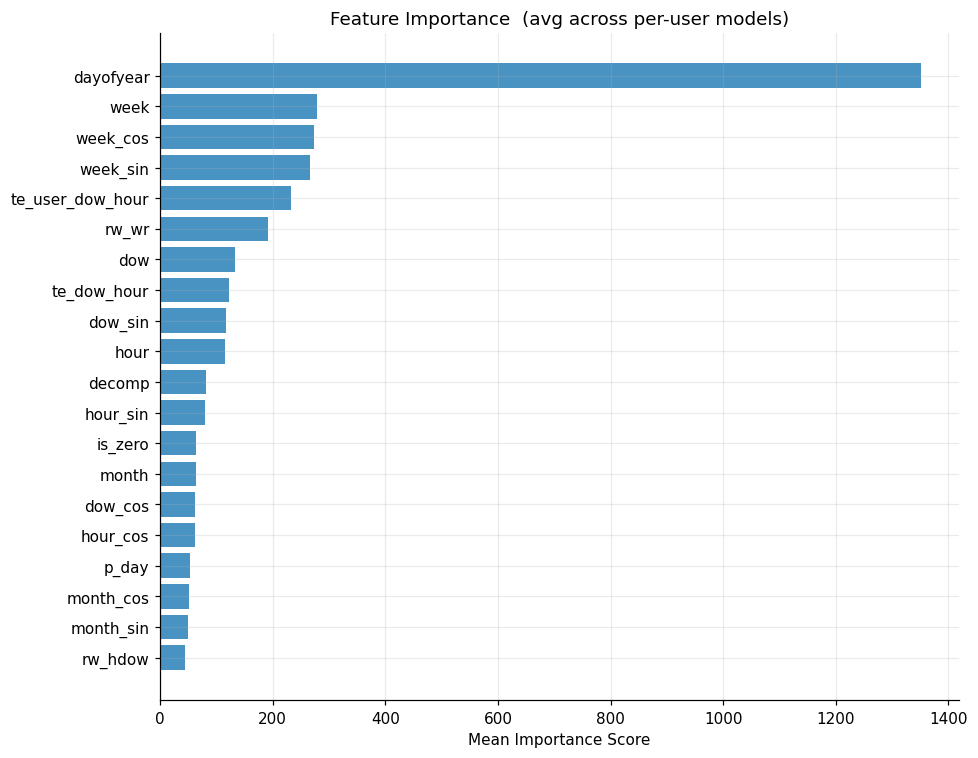

    Saved: feature_importance.png


In [10]:
print("\n[8/8] Feature importance + saving submission...")

importances = {}
for uid in sorted(train["unique_id"].unique()):
    tr_u = train_f[train_f["unique_id"]==uid][FEAT_COLS+["y_b"]].dropna()
    if tr_u["y_b"].sum() < 5 or tr_u["y_b"].nunique() < 2: continue
    m = LGBMClassifier(**LGBM_PARAMS)
    m.fit(tr_u[FEAT_COLS], tr_u["y_b"])
    importances[uid] = dict(zip(FEAT_COLS, m.feature_importances_))

if importances:
    fi = (pd.DataFrame(importances).T.mean()
          .sort_values(ascending=True).tail(20))
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(fi.index, fi.values, color=BLUE, alpha=0.85)
    ax.set_title("Feature Importance  (avg across per-user models)")
    ax.set_xlabel("Mean Importance Score")
    plt.tight_layout()
    plt.savefig("feature_importance.png", bbox_inches="tight")
    plt.show()
    print("    Saved: feature_importance.png")


In [14]:
sub = test_pred[["unique_id", "ds", "y_prob"]].copy()
sub["ds"] = pd.to_datetime(sub["ds"]).dt.strftime("%Y-%m-%d %H:%M:%S")
sub.to_csv("level1_submission_lightgbm.csv", sep=";", index=False)

print(f"\n    Saved: level1_submission_lightgbm.csv")
print(f"    Rows       : {len(sub):,}")
print(f"    Prob range : [{sub['y_prob'].min():.5f},  {sub['y_prob'].max():.4f}]")
print(f"    Mean prob  : {sub['y_prob'].mean():.5f}")
print()
print(sub.head(10).to_string(index=False))



    Saved: level1_submission_lightgbm.csv
    Rows       : 21,960
    Prob range : [0.00001,  0.8047]
    Mean prob  : 0.05471

                       unique_id                  ds   y_prob
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 00:00:00 0.000010
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 01:00:00 0.000010
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 02:00:00 0.000010
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 03:00:00 0.000010
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 04:00:00 0.000655
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 05:00:00 0.060035
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 06:00:00 0.529841
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 07:00:00 0.529513
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 08:00:00 0.532709
1679091c5a880faf6fb5e6087eb1b2dc 2025-04-01 09:00:00 0.534809


In [15]:
try:
    from google.colab import files
    files.download('level1_submission_lightgbm.csv')
    print('Download started')
except ImportError:
    print('File saved locally: level1_submission_lightgbm.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started
